# Lesson 02 — Learning Logistic Regression: Who is winning the chase?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kishan19/ds-with-cricket-basic-ML/blob/main/lessons/02-chase-win-probability-logistic-regression/lesson.ipynb)

**Concept:** logistic regression, and why a forecast should be a probability
**Cricket question:** halfway through a chase, who is going to win?
**Data:** IPL ball-by-ball, Cricsheet, 2008–present

> Sections are fixed by `docs/lesson-contract.md`. Do not add, remove or reorder them.

In [1]:
# Colab setup. Does nothing when run locally (use `make setup` and `make data` / `make hawkeye`).
# On Colab: clone the repo, install `cricketml`, and download this lesson's data.
import os
import subprocess
import sys

if "google.colab" in sys.modules:
    REPO = "/content/ds-with-cricket-basic-ML"
    URL = "https://github.com/kishan19/ds-with-cricket-basic-ML.git"
    if not os.path.exists(REPO):
        subprocess.run(["git", "clone", "--depth=1", URL, REPO], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", REPO], check=True)
    os.environ["CRICKETML_ROOT"] = REPO  # so cricketml finds data/ inside the clone

    from cricketml.data import cricsheet

    cricsheet.build("ipl")

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression, LogisticRegression

from cricketml import SEED
from cricketml.data import load_deliveries, load_matches
from cricketml.evaluation import classification_report_row, temporal_split
from cricketml.features import chase_states
from cricketml.models import MajorityClass, RequiredRateRule
from cricketml.viz import CATEGORICAL, annotate_source, use_theme

use_theme()
pd.set_option("display.precision", 3)
SEED

1983

## 1. The cricket question

Eden Gardens, April 2024. Kolkata have made 223. After 14 overs Rajasthan are
128 for 6, needing 96 off the last 36 balls. Everyone watching has already
decided who is winning, and most of them would put a number on it: *"that's 90%
Kolkata, surely."*

That number is a forecast. This lesson builds one from every IPL chase on
record, then asks two questions of it: does it rank the chases better than the
commentator's rule of thumb, and when it says 90%, does it mean 90%?

Lesson 01 predicted a number, the final total. This question has only two
answers, win or lose, so the forecast has to be a probability. That one change
is the whole of logistic regression.

(Keep an eye on this chase. It comes back in section 6.)

## 2. The data

**Grain:** one row per chase per completed over, holding only what the
scoreboard showed at that moment: the target, runs needed, balls left and
wickets in hand. The label is whether the chasing side went on to win.
`cricketml.features.chase_states` builds it, and keeps a row only while the
chase is still live, so the over in which it was won or lost does not appear.

**Exclusions, and why:**

- **Ties and no results.** A tie has no winner of the chase itself (the super
  over decides the match), and a washout has no outcome at all.
- **Rain-revised (D/L) targets.** The side was not chasing first-innings total
  plus one, so "runs needed" would be wrong on every row of the match.
- **Super overs** are dropped by `load_deliveries`.

In [3]:
deliveries = load_deliveries("ipl")
matches = load_matches("ipl")
states = chase_states(deliveries, matches)

no_winner = states["result"].notna()
rain_rule = states["method"].notna()
df = states.loc[~no_winner & ~rain_rule].reset_index(drop=True)

print(f"{states.match_id.nunique():,} chases, {len(states):,} end-of-over states")
print(f"  tie or no result:  {states.loc[no_winner, 'match_id'].nunique():>3} chases dropped")
print(f"  D/L target:        {states.loc[rain_rule, 'match_id'].nunique():>3} chases dropped")
print(f"{df.match_id.nunique():,} chases kept, {df.date.min():%Y} to {df.date.max():%Y}")

SCOREBOARD = ["runs_needed", "balls_left", "wickets_left"]
eden = df.loc[
    df["date"].eq(pd.Timestamp("2024-04-16")) & df["batting_team"].eq("Rajasthan Royals")
].set_index("overs_done")
eden[["target", "runs_so_far", "wickets_down", *SCOREBOARD, "chasing_won"]].loc[[6, 10, 14, 18]]

1,237 chases, 21,939 end-of-over states
  tie or no result:   19 chases dropped
  D/L target:         23 chases dropped
1,195 chases kept, 2008 to 2026


,target,runs_so_far,wickets_down,runs_needed,balls_left,wickets_left,chasing_won
overs_done,,,,,,,
6,224,76,2,148,84,8,1
10,224,109,4,115,60,6,1
14,224,128,6,96,36,4,1
18,224,196,8,28,12,2,1


So what this means is that one match becomes up to nineteen rows, and those
rows are not independent: they share a pitch, two teams and one result. The
split below keeps every match whole and puts the most recent fifth of the
dates in the test set, so the model is judged on chases it has never seen,
played after everything it trained on.

In [4]:
train, test = temporal_split(df, test_size=0.2)
print(f"train {train.match_id.nunique():,} chases ({len(train):,} states), up to {train.date.max():%d %b %Y}")
print(f"test  {test.match_id.nunique():,} chases ({len(test):,} states), from  {test.date.min():%d %b %Y}")

train 975 chases (17,499 states), up to 17 May 2023
test  220 chases (3,877 states), from  18 May 2023


## 3. The naive answer

Two answers that need no machine learning:

1. **The base rate.** Chasing sides win about 54% of IPL matches, so say that
   every time. It knows nothing about the scoreboard, which makes it the floor.
2. **Ahead of the rate.** *"They need nine an over and they're going at ten."*
   If the run rate so far is at least the rate still needed, the chasing side
   is winning (`RequiredRateRule`). This is what the commentator actually says.

Two metrics matter here. **AUC** asks whether a forecast *ranks* the eventual
winners above the losers (0.5 is a coin toss, 1 is perfect). **Brier score** is
the average squared gap between the probability given and what happened, so it
also punishes overconfidence. Lower is better, and always saying 50% scores 0.25.

In [5]:
y_test = test["chasing_won"]
base = MajorityClass().fit(train, train["chasing_won"])
rule = RequiredRateRule().fit(train)

naive = pd.DataFrame([
    classification_report_row(y_test, base.predict_proba(test)[:, 1], model="Base rate"),
    classification_report_row(y_test, rule.predict_proba(test)[:, 1], model="Ahead of the rate"),
])
naive[["model", "roc_auc", "brier", "accuracy"]]

,model,roc_auc,brier,accuracy
0,Base rate,0.500,0.249,0.532
1,Ahead of the rate,0.754,0.252,0.748


The rule is right three times in four (accuracy 0.75), and it ranks chases far
better than a coin toss (AUC 0.75). But its Brier score is **worse than the base
rate**, which knows nothing about the match at all.

The reason is that the rule only ever says 0% or 100%. Each time a side behind
the rate wins anyway, it pays the maximum penalty of 1. A forecast that is
right more often but never admits doubt loses to one that knows nothing but is
honest about it. So what this means is that a model has to beat the rule on
ranking *and* on honesty, and that needs an answer between 0 and 1.

## 4. The idea

**In cricket.** A commentator who says "60–40 Kolkata" is adding up evidence.
Runs needed count against the chasing side, while balls left and wickets in
hand count for it. Each piece pushes the odds one way or the other, and the
total is turned into a percentage. A side already 95% likely to win can't get
much more likely, however many wickets it has left, so the percentage bends
flat near 0 and 100. Logistic regression is that recipe, with the data choosing
how much each piece of evidence is worth.

**Why not lesson 01's straight line?** Code a win as 1 and a loss as 0, and
linear regression will fit those numbers happily. But a straight line never
stops, so it walks straight past 0 and 1:

In [6]:
line = LinearRegression().fit(train[SCOREBOARD], train["chasing_won"])
said = line.predict(train[SCOREBOARD])
print(f"below 0%:   {(said < 0).mean():.1%} of training states, as low as {said.min():.0%}")
print(f"above 100%: {(said > 1).mean():.1%} of training states, as high as {said.max():.0%}")

below 0%:   4.6% of training states, as low as -78%
above 100%: 4.5% of training states, as high as 156%


So what this means is that one state in eleven gets a chance of winning that
cannot exist: needing 20 off 60 with nine wickets in hand comes out at 124%,
and needing 150 off 60 with three wickets left comes out at −37%. The fix is not a better line.
It is to keep the line, but squash its output into the range 0 to 1.

**In maths.** Add the evidence up as a weighted sum, the *log-odds*, and
squash it into a probability with the logistic (sigmoid) function:

$$z = \beta_0 + \beta_1\,\text{runs needed} + \beta_2\,\text{balls left} + \beta_3\,\text{wickets left}
\qquad
p = \sigma(z) = \frac{1}{1 + e^{-z}}$$

The $\beta$ are chosen to minimise the log-loss over the training states,

$$-\sum_i \big[\, y_i \log p_i + (1 - y_i) \log (1 - p_i) \,\big],$$

which charges a lot for a confident wrong answer. Unlike lesson 01 there is no
closed form, so it is solved iteratively. Each coefficient reads as a
multiplier on the odds: one more unit of $x_j$ multiplies the odds of winning
by $e^{\beta_j}$.

**The assumption, and whether cricket satisfies it.** The log-odds must be a
*straight-line* sum of the features. Cricket disagrees in one obvious place.
Runs needed and balls left matter as a **ratio**: 30 off 12 and 30 off 60 are
different chases, but a sum of the two can't express that. Section 5 tests
whether adding the required rate itself helps.

The S-shape is real, and it appears in the raw data before any model is fitted.
Take every training chase at the halfway mark:

,mean,size
required_rate,,
"(0, 6]",0.97,135
"(6, 7]",0.90,78
"(7, 8]",0.71,129
"(8, 9]",0.62,155
"(9, 10]",0.47,148
"(10, 11]",0.32,99
"(11, 12]",0.23,92
"(12, 13]",0.16,58
"(13, 14]",0.05,40


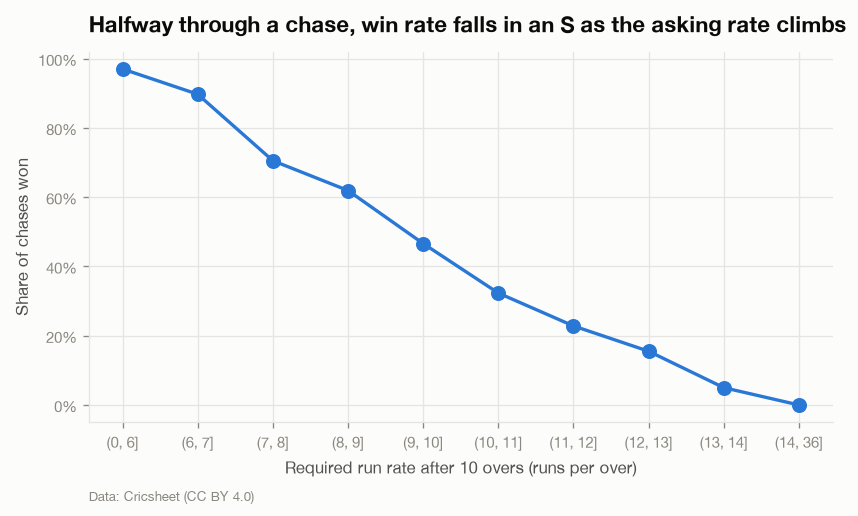

In [7]:
halfway = train.loc[train["overs_done"] == 10]
bands = pd.cut(halfway["required_rate"], bins=[0, 6, 7, 8, 9, 10, 11, 12, 13, 14, 36])
s_curve = halfway.groupby(bands, observed=True)["chasing_won"].agg(["mean", "size"])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot([str(b) for b in s_curve.index], s_curve["mean"], marker="o")
ax.set_title("Halfway through a chase, win rate falls in an S as the asking rate climbs")
ax.set_xlabel("Required run rate after 10 overs (runs per over)")
ax.set_ylabel("Share of chases won")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
annotate_source(ax)
s_curve.round(2)

So what this means is that at 8 an over chasing sides usually win, and at 12
they usually lose, and almost all the change happens in between. Near either
end, one more run an over barely moves the outcome. A straight line can't
draw that curve, but a sigmoid can.

## 5. Build it

Three numbers from the scoreboard, and nothing else:

In [8]:
model = LogisticRegression(max_iter=1_000).fit(train[SCOREBOARD], train["chasing_won"])

coefs = pd.DataFrame(
    {"log-odds per unit": model.coef_[0], "odds multiplier": np.exp(model.coef_[0])},
    index=SCOREBOARD,
)
runs_per_wicket = model.coef_[0][2] / -model.coef_[0][0]
balls_per_wicket = model.coef_[0][2] / model.coef_[0][1]
print(f"one wicket in hand is worth {runs_per_wicket:.0f} runs, or {balls_per_wicket:.0f} balls")
coefs

one wicket in hand is worth 11 runs, or 13 balls


,log-odds per unit,odds multiplier
runs_needed,-0.056,0.946
balls_left,0.047,1.048
wickets_left,0.604,1.830


Read them as cricket:

| feature | odds multiplier | what it says |
|---|---|---|
| `runs_needed` | **×0.95** per run | Every extra run needed cuts the odds by about 5%. Ten runs cut them by about 40% |
| `balls_left` | **×1.05** per ball | Every spare ball helps by about the same amount a run hurts |
| `wickets_left` | **×1.83** per wicket | A wicket in hand nearly doubles the odds |

Divide one coefficient by another and you get an exchange rate: **one wicket in
hand is worth about 11 runs, or about two overs.** With the same balls left,
needing 61 with six wickets in hand is about as good as needing 50 with five.
The model has turned the commentator's gut feel into an exchange rate.

Now the assumption from section 4. Add the required rate as a fourth feature,
so the model can see the ratio directly:

In [9]:
WITH_RATE = [*SCOREBOARD, "required_rate"]
model_rate = LogisticRegression(max_iter=1_000).fit(train[WITH_RATE], train["chasing_won"])

pd.Series(np.exp(model_rate.coef_[0]), index=WITH_RATE, name="odds multiplier")

runs_needed      0.975
balls_left       1.001
wickets_left     1.719
required_rate    0.736
Name: odds multiplier, dtype: float64

With the rate in the model, it takes over most of what runs needed and balls
left were doing: each extra run an over needed multiplies the odds by about
0.74, and `balls_left` drops to almost exactly 1, meaning no effect of its own.
The wicket is still worth a big multiplier, ×1.7. Section 6 decides whether the
extra feature actually forecasts better.

## 6. Judge it

In [10]:
results = pd.concat([
    naive,
    pd.DataFrame([
        classification_report_row(
            y_test, model.predict_proba(test[SCOREBOARD])[:, 1], model="Logistic: scoreboard"
        ),
        classification_report_row(
            y_test, model_rate.predict_proba(test[WITH_RATE])[:, 1], model="Logistic: + required rate"
        ),
    ]),
], ignore_index=True)
results[["model", "roc_auc", "avg_precision", "brier", "accuracy", "n"]]

,model,roc_auc,avg_precision,brier,accuracy,n
0,Base rate,0.500,0.532,0.249,0.532,3877
1,Ahead of the rate,0.754,0.730,0.252,0.748,3877
2,Logistic: scoreboard,0.898,0.907,0.147,0.792,3877
3,Logistic: + required rate,0.910,0.919,0.138,0.801,3877


<Axes: title={'left': "Logistic regression nearly halves the commentator's Brier score"}, xlabel='Brier score on chases from May 2023 (lower is better)'>

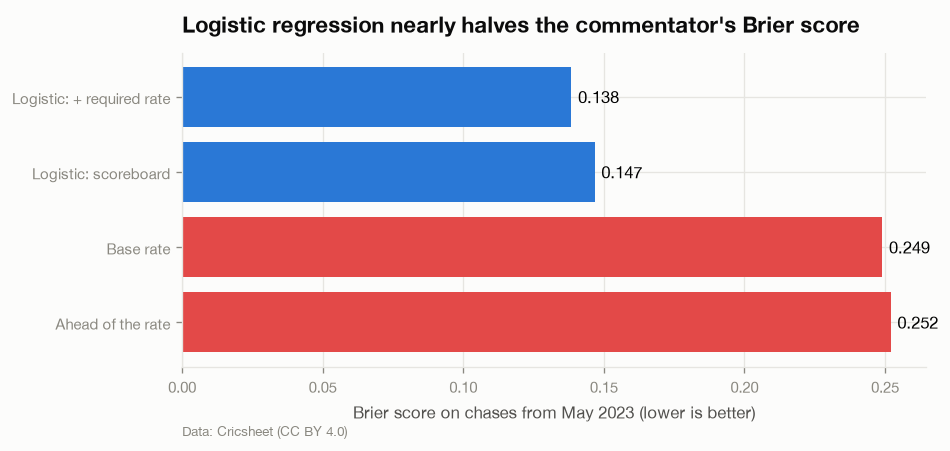

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.4))
ordered = results.set_index("model")["brier"].sort_values(ascending=False)
ax.barh(ordered.index, ordered.to_numpy(), color=[CATEGORICAL[7]] * 2 + [CATEGORICAL[0]] * 2)
ax.bar_label(ax.containers[0], fmt="%.3f", padding=4)
ax.set_title("Logistic regression nearly halves the commentator's Brier score")
ax.set_xlabel("Brier score on chases from May 2023 (lower is better)")
annotate_source(ax)

**In prose.** Both logistic models beat both baselines on every column. The
headline is the Brier score: 0.252 for the commentator's rule against 0.138
for logistic regression with the required rate, a cut of 45%. Ranking improves
too, from an AUC of 0.75 to 0.91, so the model is not only more honest but
better at telling winning chases from losing ones.

The required rate earns its place, but only just: AUC 0.898 → 0.910 and Brier
0.147 → 0.138. That is the size of the ratio effect section 4 predicted, real
but small, because runs and balls together already carry most of it.

Accuracy barely moves (0.75 → 0.80), which shows why it is the wrong metric
here. Accuracy only checks which side of 50% a forecast lands on, so it
can't tell an honest 55% from a reckless 100%.

Now the Eden Gardens chase, over by over, through the eyes of both forecasts:

<Axes: title={'left': 'Rajasthan were given 2% with 36 balls left. They won off the last ball'}, xlabel='Overs completed in the chase', ylabel="Rajasthan's chance of winning">

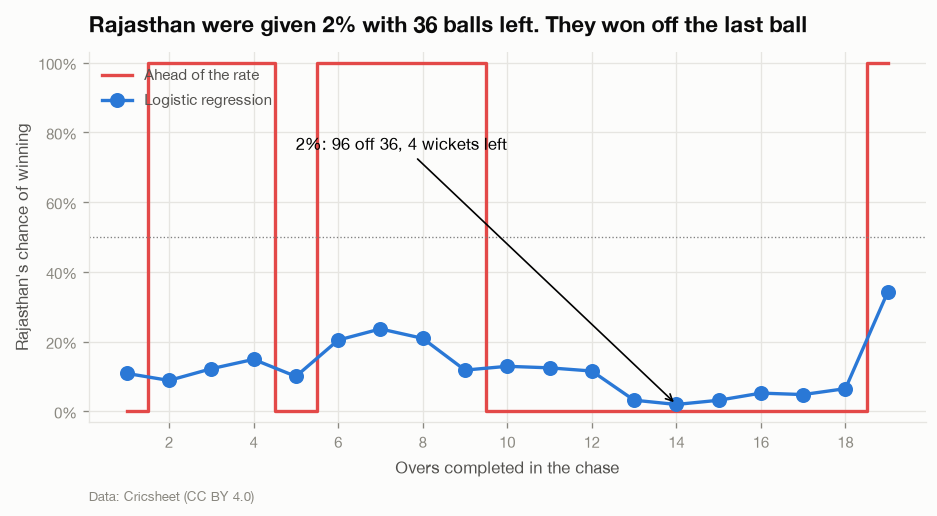

In [12]:
eden_p = model_rate.predict_proba(eden[WITH_RATE])[:, 1]
eden_rule = rule.predict_proba(eden)[:, 1]

fig, ax = plt.subplots(figsize=(9, 4))
ax.step(eden.index, eden_rule, where="mid", color=CATEGORICAL[7], label="Ahead of the rate")
ax.plot(eden.index, eden_p, marker="o", label="Logistic regression")
ax.axhline(0.5, color="grey", linewidth=0.8, linestyle=":")
low = eden.index[eden_p.argmin()]
ax.annotate(f"{eden_p.min():.0%}: {eden.loc[low, 'runs_needed']} off {eden.loc[low, 'balls_left']}, "
            f"{eden.loc[low, 'wickets_left']} wickets left",
            xy=(low, eden_p.min()), xytext=(low - 9, 0.75), arrowprops={"arrowstyle": "->"})
ax.set_title("Rajasthan were given 2% with 36 balls left. They won off the last ball")
ax.set_xticks(range(2, 20, 2))
ax.set_xlabel("Overs completed in the chase")
ax.set_ylabel("Rajasthan's chance of winning")
ax.set_ylim(-0.03, 1.03)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.legend(loc="upper left")
annotate_source(ax)

So what this means is that the commentator's rule lurched between certain
win and certain loss five times in one chase, and had Rajasthan dead and
buried from the 10th over to the 18th. The model never swung like that. It
stayed gloomy but put a number on the gloom: 10–25% while wickets stood, then
2–7% once the sixth fell, until the 19th over. Jos Buttler's unbeaten 107 made
the 2% happen. That is not the model being
wrong. Of every hundred chases it gives 2%, it *expects* about two to be won.
Whether it is right about that is a question for the whole test set, not one
match, and section 7 asks it.

## 7. What it gets wrong

- **It is not calibrated on the chases it was tested on.** Group the test
  states by the probability the model gave, and compare with how often the
  chasing side actually won:

In [13]:
judged = pd.concat([train.assign(era="train: 2008 to May 2023"), test.assign(era="test: May 2023 to 2026")])
judged["said"] = model_rate.predict_proba(judged[WITH_RATE])[:, 1]
bucket = pd.cut(judged["said"], bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0])
(
    judged.groupby(["era", bucket], observed=True)
    .agg(model_said=("said", "mean"), chasers_won=("chasing_won", "mean"), states=("said", "size"))
    .round(2)
)

model_said  chasers_won  states
era                     said                                       
test: May 2023 to 2026  (0.0, 0.2]        0.07         0.12    1414
                        (0.2, 0.4]        0.29         0.48     625
                        (0.4, 0.6]        0.50         0.70     512
                        (0.6, 0.8]        0.71         0.88     516
                        (0.8, 1.0]        0.91         0.97     810
train: 2008 to May 2023 (0.0, 0.2]        0.08         0.08    3984
                        (0.2, 0.4]        0.30         0.32    2643
                        (0.4, 0.6]        0.50         0.49    2732
                        (0.6, 0.8]        0.70         0.69    3279
                        (0.8, 1.0]        0.91         0.91    4861

  On the training years the two columns agree almost exactly: when the model
  says 50%, chasing sides win 49%. On the test years, when it says 50%, they
  win **70%**, and when it says 30%, they win 48%. The ranking is still good,
  but the percentages are stale. Something about chasing changed in the most
  recent seasons, and a model trained on the old game keeps
  underrating chasers. The test period starts with the 2023 season, which also
  introduced the Impact Player rule (a substitute batter, so effectively deeper
  batting). That fits the pattern, because it makes a lost wicket cost less,
  but this lesson doesn't test it. → *calibration, and distribution shift*
- **It knows the score, not the players.** 96 off 36 with a set batter still
  in is not 96 off 36 with two tail-enders at the crease. → *feature engineering: who is in, and
  who is left to bowl*
- **It ignores the ground and the conditions.** Dew, a short boundary and a flat
  pitch all make chasing easier, and none are in the features.
  → *feature engineering*
- **Its rows are not independent.** Nineteen states from one match share one
  result, so the training data looks bigger than it is. The match-by-date split
  keeps the *test* honest, but the model still gives one freakish chase nineteen
  votes. → *grouped validation, `match_group_cv`*
- **The log-odds are a straight-line sum.** The required rate helped, but the
  real shape is richer. A wicket in the 19th over is not worth the same as a
  wicket in the 2nd. → *interactions, trees*

**Next:** lessons 01 and 02 both learnt from an answer key: the final total, and
who won. Lesson 03 takes the answer key away and asks what the data can find on
its own, with no labels at all. That is clustering.

## Appendix — logistic regression from scratch (optional)

Everything above calls `sklearn.linear_model.LogisticRegression`. Below is the
same algorithm written out by hand, first on ten made-up chases small enough to
draw, then on every real one. This isn't one of the seven fixed sections; skip
it if the lesson has already made sense.

Ten chases at the halfway mark, each one a required rate and a result. They are
hand-placed to look like the real chart in section 4, including two upsets: a
loss at 9 an over and a win at 11.

In [14]:
toy = pd.DataFrame({
    "required_rate": [6.0, 7.0, 7.5, 8.5, 9.0, 9.5, 10.5, 11.0, 12.0, 13.5],
    "chasing_won":   [1,   1,   1,   1,   0,   1,   0,    1,    0,    0],
})
x, y = toy["required_rate"].to_numpy(), toy["chasing_won"].to_numpy()
toy.T

,0,1,2,3,4,5,6,7,8,9
required_rate,6.0,7.0,7.5,8.5,9.0,9.5,10.5,11.0,12.0,13.5
chasing_won,1.0,1.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0


**Step 1. Fit the straight line anyway.** It is lesson 01's model, so it is the
honest first try.

In [15]:
toy_line = LinearRegression().fit(x[:, None], y)
for rate in [4, 16]:
    print(f"needing {rate:>2} an over: the line says {toy_line.predict([[rate]])[0]:.0%}")

needing  4 an over: the line says 140%
needing 16 an over: the line says -36%


So what this means is that the line breaks on chases just outside the ten it
saw: a chance of more than 100% at 4 an over, and less than zero at 16.

**Step 2. Squash it.** Keep the straight line, $z = \beta_0 + \beta_1 x$, but call
its output the *log-odds* and pass it through the sigmoid. Whatever $z$ is, the
answer lands between 0 and 1, and $z = 0$ means exactly 50%.

In [16]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

pd.Series(sigmoid(np.array([-6, -2, -1, 0, 1, 2, 6])), index=[-6, -2, -1, 0, 1, 2, 6],
          name="probability").rename_axis("log-odds z").round(3)

log-odds z
-6    0.002
-2    0.119
-1    0.269
 0    0.500
 1    0.731
 2    0.881
 6    0.998
Name: probability, dtype: float64

**Step 3. Score a guess.** Log-loss charges $-\log p$ when the chase was won
and $-\log(1 - p)$ when it was lost. Being wrong costs more the more sure you
were:

In [17]:
for said in [0.6, 0.9, 0.99]:
    print(f"said {said:.0%} and they lost: costs {-np.log(1 - said):.2f}")

said 60% and they lost: costs 0.92
said 90% and they lost: costs 2.30
said 99% and they lost: costs 4.61


So what this means is that going from 90% to 99% sure, and being wrong, costs
twice as much. Log-loss is what makes the model honest about doubt, which is
exactly what the commentator's rule lacked in section 3.

**Step 4. Learn by walking downhill.** Start at $\beta_0 = \beta_1 = 0$, which
says 50% for every chase. The slope of the log-loss is the average of
$(p_i - y_i)$, the miss on each chase, times its input. Step against the slope,
recompute, repeat. That is gradient descent, and it is all `.fit()` does.

The required rate is centred first (9.5 subtracted from it), so the intercept
reads as "a chase at 9.5 an over" rather than the meaningless "a chase at 0 an
over".

In [18]:
def fit_logistic(X, y, learning_rate=0.5, steps=2_000):
    """Gradient descent on the log-loss. X needs a column of ones for the intercept."""
    beta = np.zeros(X.shape[1])
    history = []
    for step in range(steps + 1):
        p = sigmoid(X @ beta)
        loss = -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
        history.append({"step": step, **{f"b{j}": b for j, b in enumerate(beta)}, "log-loss": loss})
        beta = beta - learning_rate * X.T @ (p - y) / len(y)
    return beta, pd.DataFrame(history).set_index("step")

CENTRE = 9.5
X_toy = np.column_stack([np.ones(len(x)), x - CENTRE])
beta, history = fit_logistic(X_toy, y)
history.loc[[0, 1, 2, 5, 10, 50, 100, 2_000]].round(3)

,b0,b1,log-loss
step,,,
0,0.000,0.000,0.693
1,0.050,-0.362,0.503
2,0.092,-0.523,0.459
5,0.192,-0.733,0.425
10,0.313,-0.855,0.414
50,0.599,-0.958,0.407
100,0.623,-0.964,0.406
2000,0.625,-0.964,0.406


So what this means is that most of the learning happens in the first ten
steps. After about a hundred the numbers stop moving: the walk has reached the
bottom of the hill.

<Axes: title={'left': 'The line leaves 0 and 1 behind. The S-curve never does'}, xlabel='Required run rate after 10 overs (runs per over)', ylabel='Chance of winning the chase'>

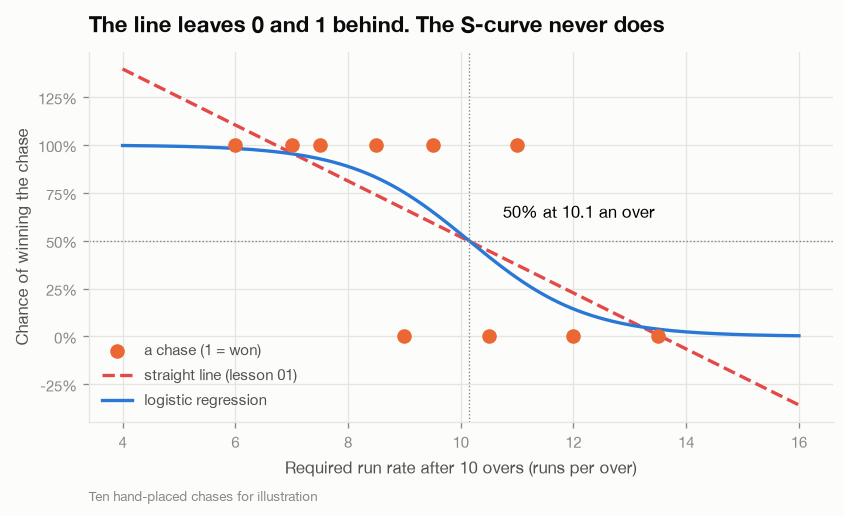

In [19]:
tipping_point = CENTRE - beta[0] / beta[1]
grid = np.linspace(4, 16, 200)

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(x, y, s=60, color=CATEGORICAL[1], zorder=3, label="a chase (1 = won)")
ax.plot(grid, toy_line.predict(grid[:, None]), color=CATEGORICAL[7], linestyle="--",
        label="straight line (lesson 01)")
ax.plot(grid, sigmoid(beta[0] + beta[1] * (grid - CENTRE)), label="logistic regression")
ax.axhline(0.5, color="grey", linewidth=0.8, linestyle=":")
ax.axvline(tipping_point, color="grey", linewidth=0.8, linestyle=":")
ax.annotate(f"50% at {tipping_point:.1f} an over", xy=(tipping_point, 0.5),
            xytext=(tipping_point + 0.6, 0.62))
ax.set_title("The line leaves 0 and 1 behind. The S-curve never does")
ax.set_xlabel("Required run rate after 10 overs (runs per over)")
ax.set_ylabel("Chance of winning the chase")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.legend(loc="lower left")
annotate_source(ax, "Ten hand-placed chases for illustration")

So what this means is that on these ten chases, the side needing about 10 an
over at halfway is a coin toss. Each extra run an over multiplies the odds by
$e^{\beta_1}$, about 0.38.

**Step 5. Check it against the library.** `C=np.inf` switches off
scikit-learn's default regularisation, so both are solving exactly the same
problem. Then the same function on all 17,499 real training states, with each
feature standardised for the walk and the coefficients converted back into
cricket units afterwards:

In [20]:
toy_sk = LogisticRegression(C=np.inf).fit(x[:, None], y)
print(f"toy, slope per run an over:  scratch {beta[1]:.4f}   scikit-learn {toy_sk.coef_[0][0]:.4f}")

X_real = train[SCOREBOARD].to_numpy(float)
mean, std = X_real.mean(axis=0), X_real.std(axis=0)
beta_real, _ = fit_logistic(np.column_stack([np.ones(len(X_real)), (X_real - mean) / std]),
                            train["chasing_won"].to_numpy(), steps=3_000)
real_sk = LogisticRegression(C=np.inf, max_iter=1_000).fit(train[SCOREBOARD], train["chasing_won"])
pd.DataFrame({"from scratch": beta_real[1:] / std, "scikit-learn": real_sk.coef_[0]},
             index=SCOREBOARD).round(4)

toy, slope per run an over:  scratch -0.9645   scikit-learn -0.9645


,from scratch,scikit-learn
runs_needed,-0.056,-0.056
balls_left,0.047,0.047
wickets_left,0.605,0.605


The two agree to three decimal places, and both match section 5's model. So
the model that priced a wicket at 11 runs is nothing more than a straight line,
a squash, a scoring rule, and a few thousand small steps downhill.